# Fig. 4 H-I and Supplementary Fig. S5: recurring k-gram sequences in starling song

A k-gram is a run of k consecutive syllables. For each bird and condition, a k-gram is **selected** if it
occurs in at least 1% of that condition's bouts and at least twice as often as a first-order Markov chain
built from the bird's own syllable and transition probabilities predicts.

* **Fig. 4H** ISI outside minus inside selected k-grams, by condition and k (Table 2).
* **Fig. 4I** size of the k-gram space: all orderings, Markov-reachable, identified, selected.
* **Supp. S5** A leave-one-out; B split-half stability; C selection outcomes; D fold cutoff;
  E prevalence distribution; F prevalence threshold.

Input: `kgram_data.pkl`, written by Cells K1-K5 of `data_figs`.

In [1]:
# Cell 1: settings, data
import os
import pickle
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from statsmodels.stats.multitest import multipletests

# Paths relative to the repository, so a fresh clone runs without edits (from the repo folder or
# from notebooks/). To use other copies, e.g. on the cluster: export HELIOX_DATA_DIR=/path/to/data/derived
REPO = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
DATA_DIR = os.environ.get('HELIOX_DATA_DIR', os.path.join(REPO, 'data'))
FIG_DIR = os.environ.get('HELIOX_FIG_DIR', os.path.join(REPO, 'figures'))
DATA_PATH = os.path.join(DATA_DIR, 'kgram_data.pkl')
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({'font.size': 15, 'axes.titlesize': 19, 'axes.labelsize': 17, 'xtick.labelsize': 15,
                     'ytick.labelsize': 15, 'legend.fontsize': 14, 'axes.spines.top': False,
                     'axes.spines.right': False, 'savefig.dpi': 300, 'savefig.bbox': 'tight'})
K_COLORS = {3: 'seagreen', 4: '#1FA5A0', 5: '#1A85B5', 6: '#1460A0', 7: '#0D3E8A', 8: '#062070'}
COND_STYLE = {'heliox': '-', 'regair': '--'}
COND_LABEL = {'heliox': 'Heliox', 'regair': 'RegAir'}

with open(DATA_PATH, 'rb') as f:
    data = pickle.load(f)
kgrams, space, isi_by_k, stability = (data[n] for n in ['kgrams', 'space', 'isi_by_k', 'stability'])
kgrams = kgrams.astype({'bird': str, 'condition': str})
SET = data['meta']['settings']
KS = SET['KS']
print(f"{len(kgrams)} k-grams ({int(kgrams['selected'].sum())} selected) from {kgrams['bird'].nunique()} birds; "
      f"made {data['meta']['created']}")
print({n: SET[n] for n in ['PREVALENCE', 'FOLD_CUT', 'MIN_SELECTED', 'N_SPLITS', 'REGAIRB_AS_REGAIR']})


def stars(p):
    return '****' if p < 1e-4 else '***' if p < 1e-3 else '**' if p < 1e-2 else '*' if p < 0.05 else 'ns'


def fit_ml(formula, df):
    """ML fit with bird as random intercept, trying optimizers in the original order until one works."""
    model = smf.mixedlm(formula, df, groups=df['bird'])
    for method in ['lbfgs', 'bfgs', 'powell', 'cg', 'nm']:
        try:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                return model.fit(reml=False, method=method, maxiter=2000, disp=False)
        except Exception as problem:
            last = problem
    raise RuntimeError(f'{formula}: no optimizer worked ({last})')


def k_legend(ax, ks=KS, conditions=True, **kw):
    handles = [Line2D([0], [0], color=K_COLORS[k], lw=3, label=f'k = {k}') for k in ks]
    if conditions:
        handles += [Line2D([0], [0], color='0.2', lw=2.5, ls=COND_STYLE[c], label=COND_LABEL[c]) for c in COND_STYLE]
    ax.legend(handles=handles, frameon=False, **kw)

174540 k-grams (41920 selected) from 6 birds; made 2026-10-11T12:20:04
{'PREVALENCE': 0.01, 'FOLD_CUT': 2.0, 'MIN_SELECTED': 10, 'N_SPLITS': 50, 'REGAIRB_AS_REGAIR': True}


In [2]:
# Cell 2: ISI outside vs inside selected k-grams (Fig. 4H, Table 2, Supp. S5A)
# Each bird gives two numbers per condition and k: its median ISI inside selected k-grams and
# outside them. Within each condition: isi_ms ~ is_outside + (1 | bird), so the is_outside term is
# outside - inside. Only birds with enough selected k-grams in both conditions enter (in_model).
def outside_minus_inside(rows):
    """Fit one condition at one k. `rows`: one row per bird with its two medians (s)."""
    rows = rows.dropna(subset=['median_isi_inside', 'median_isi_outside'])
    long = pd.DataFrame([dict(bird=r.bird, is_outside=o, isi_ms=1000 * (r.median_isi_outside if o else r.median_isi_inside))
                         for r in rows.itertuples() for o in (0, 1)])
    res = fit_ml('isi_ms ~ is_outside', long)
    lo, hi = res.conf_int().loc['is_outside']
    return dict(beta_ms=res.params['is_outside'], se_ms=res.bse['is_outside'], z=res.tvalues['is_outside'],
                p=res.pvalues['is_outside'], lo_ms=lo, hi_ms=hi, n_birds=rows['bird'].nunique())


in_model = isi_by_k[isi_by_k['in_model']]
table2 = []
for k in KS:
    at_k = in_model[in_model['k'] == k]
    usable = at_k.dropna(subset=['median_isi_inside', 'median_isi_outside']).groupby('condition')['bird'].nunique()
    if usable.get('heliox', 0) < 2 or usable.get('regair', 0) < 2:
        print(f'k = {k}: fewer than two birds with ISIs inside and outside in a condition; left out')
        continue
    for cond in ['heliox', 'regair']:
        table2.append(dict(k=k, condition=cond, **outside_minus_inside(at_k[at_k['condition'] == cond])))
table2 = pd.DataFrame(table2)
for c in ['beta', 'se', 'lo', 'hi']:
    table2[c] = table2[c + '_ms'] / 1000                       # seconds, as in Table 2 and Fig. 4H
# Benjamini-Hochberg across the six k, separately for heliox and regular air
table2['q_bh'] = table2.groupby('condition')['p'].transform(lambda p: multipletests(p, method='fdr_bh')[1])
print('Table 2: outside - inside ISI (s)')
print(table2[['k', 'condition', 'beta', 'se', 'z', 'p', 'q_bh', 'n_birds']].round(5).to_string(index=False))

# Leave-one-out (Supp. S5A): refit the heliox model without each bird in turn.
loo = []
for bird in sorted(isi_by_k['bird'].unique()):
    for k in KS:
        rows = in_model[(in_model['k'] == k) & (in_model['condition'] == 'heliox') & (in_model['bird'] != bird)]
        if rows.dropna(subset=['median_isi_inside', 'median_isi_outside'])['bird'].nunique() >= 2:
            loo.append(dict(excluded=bird, k=k, **outside_minus_inside(rows)))
loo = pd.DataFrame(loo)
loo_summary = loo.groupby('k')['beta_ms'].agg(['min', 'max', 'mean'])
loo_summary['range / mean'] = (loo_summary['max'] - loo_summary['min']) / loo_summary['mean']
print('\nleave-one-out, heliox outside - inside (ms):')
print(loo_summary.round(2).to_string())

Table 2: outside - inside ISI (s)
 k condition     beta      se        z       p    q_bh  n_birds
 3    heliox -0.01250 0.01453 -0.86026 0.38965 0.38965        6
 3    regair -0.00750 0.01356 -0.55301 0.58026 0.89719        6
 4    heliox  0.03775 0.01295  2.91519 0.00355 0.00717        6
 4    regair -0.00367 0.01395 -0.26293 0.79261 0.89719        6
 5    heliox  0.07117 0.01454  4.89405 0.00000 0.00001        6
 5    regair  0.00367 0.01246  0.29427 0.76855 0.89719        6
 6    heliox  0.06250 0.02439  2.56237 0.01040 0.01559        6
 6    regair  0.00175 0.01354  0.12921 0.89719 0.89719        6
 7    heliox  0.08950 0.03073  2.91239 0.00359 0.00717        5
 7    regair  0.00520 0.01742  0.29847 0.76534 0.89719        5
 8    heliox  0.07890 0.03297  2.39283 0.01672 0.02006        5
 8    regair  0.00360 0.01904  0.18906 0.85005 0.89719        5

leave-one-out, heliox outside - inside (ms):
     min     max   mean  range / mean
k                                    
3 -25.40   -

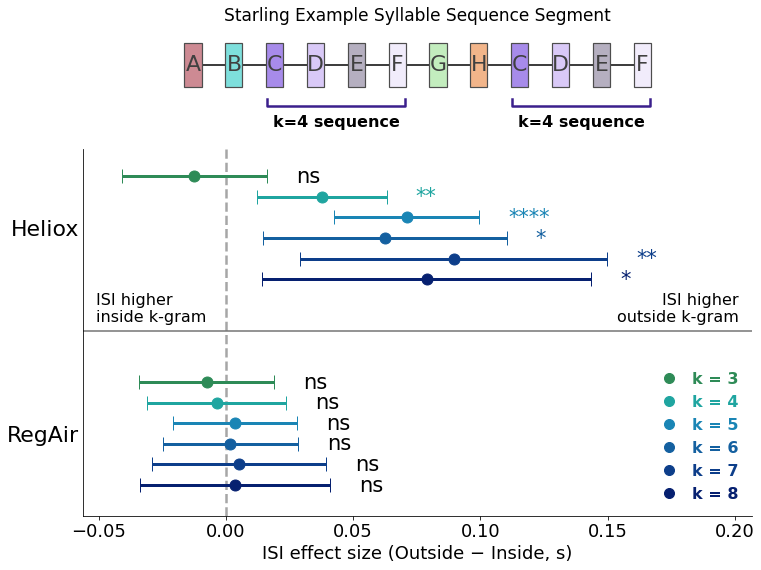

In [3]:
# Cell 3: Fig. 4H, schematic (top) and outside - inside ISI by condition and k (bottom)
fig, (top, ax) = plt.subplots(2, 1, figsize=(12, 9), gridspec_kw=dict(height_ratios=[1, 3.3], hspace=0.05))

# ---- schematic: one recurring k = 4 sequence (C-D-E-F) twice in a bout -----------------------
SCHEME = list('ABCDEFGHCDEF')
BOX = {'A': '#CD8A93', 'B': '#7EDFDC', 'C': '#A78BEA', 'D': '#D9C9F7', 'E': '#B5AFC0', 'F': '#F1ECFB',
       'G': '#C3EDBE', 'H': '#F2B58A'}
top.plot([0, len(SCHEME) - 1], [0, 0], color='k', lw=1.5, zorder=1)
for i, s in enumerate(SCHEME):
    top.add_patch(Rectangle((i - 0.21, -0.32), 0.42, 0.64, facecolor=BOX[s], edgecolor='0.3', lw=1.2, zorder=2))
    top.text(i, 0, s, ha='center', va='center', fontsize=22, color='0.25', zorder=3)
for start in (2, 8):
    x0, x1 = start - 0.2, start + 3.2
    top.plot([x0, x0, x1, x1], [-0.5, -0.6, -0.6, -0.5], color='#3B1F8C', lw=2.5)
    top.text((x0 + x1) / 2, -0.72, 'k=4 sequence', ha='center', va='top', fontsize=16, fontweight='bold')
top.set_xlim(-2.7, len(SCHEME) + 1.7)
top.set_ylim(-1.05, 0.55)
top.set_title('Starling Example Syllable Sequence Segment', fontsize=17)
top.axis('off')

# ---- outside - inside ISI --------------------------------------------------------------------
ks = sorted(table2['k'].unique())
offset = dict(zip(ks, np.linspace(0.25, -0.25, len(ks))))       # k = 3 at the top of each condition
row = {'heliox': 1.0, 'regair': 0.0}
xspan = table2['hi'].max() - table2['lo'].min()
for r in table2.itertuples():
    y = row[r.condition] + offset[r.k]
    ax.errorbar(r.beta, y, xerr=[[r.beta - r.lo], [r.hi - r.beta]], fmt='o', color=K_COLORS[r.k],
                elinewidth=3, capsize=7, markersize=11, zorder=3)
    s = stars(r.p)
    ax.text(r.hi + 0.06 * xspan, y, s, ha='left', va='center', fontsize=21,
            color=K_COLORS[r.k] if s != 'ns' else 'black')
ax.axvline(0, color='0.65', ls='--', lw=2.5, zorder=1)
ax.axhline(0.5, color='0.45', lw=1.5, zorder=1)
ax.set_yticks([1.0, 0.0])
ax.set_yticklabels(['Heliox', 'RegAir'], fontsize=22)
ax.tick_params(axis='y', length=0)
ax.tick_params(axis='x', labelsize=18)
ax.set_xlabel('ISI effect size (Outside − Inside, s)', fontsize=18)
ax.set_xlim(min(table2['lo'].min(), 0) - 0.08 * xspan, max(table2['hi'].max(), 0) + 0.3 * xspan)
ax.set_ylim(-0.4, 1.38)
for x, ha, text in [(0.02, 'left', 'ISI higher\ninside k-gram'), (0.98, 'right', 'ISI higher\noutside k-gram')]:
    # x in axes fraction, y in data units: just above the line between the two conditions
    ax.text(x, 0.53, text, transform=ax.get_yaxis_transform(), ha=ha, va='bottom', fontsize=16)
handles = [Line2D([0], [0], color=K_COLORS[k], marker='o', lw=0, markersize=10, label=f'k = {k}') for k in ks]
leg = ax.legend(handles=handles, frameon=False, loc='lower right', fontsize=16, handletextpad=0.4)
for text, k in zip(leg.get_texts(), ks):
    text.set_color(K_COLORS[k])
    text.set_fontweight('bold')
fig.savefig(os.path.join(FIG_DIR, 'fig4H_kgram_isi.png'))
fig.savefig(os.path.join(FIG_DIR, 'fig4H_kgram_isi.pdf'))
plt.show()

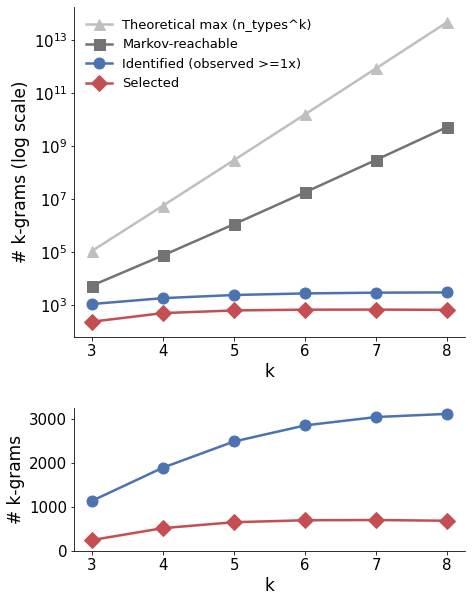

selected as % of Markov-reachable (mean bird):
condition   heliox   regair
k                          
3             4.71     4.02
4            0.635    0.686
5           0.0479    0.064
6          0.00292  0.00488
7          0.00016 0.000346
8         8.34e-06 2.35e-05


In [4]:
# Cell 4: Fig. 4I, how many k-grams each tier holds, by k
# Averaged over birds within each condition, then over the two conditions.
TIERS = [('theoretical_max', 'Theoretical max (n_types^k)', '0.75', '^'),
         ('markov_reachable', 'Markov-reachable', '0.45', 's'),
         ('n_identified', 'Identified (observed >=1x)', '#4C72B0', 'o'),
         ('n_selected', 'Selected', '#C44E52', 'D')]
cols = [t[0] for t in TIERS]
tier_means = space.astype({c: float for c in cols}).groupby(['condition', 'k'])[cols].mean().groupby('k').mean()

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(7, 10), gridspec_kw=dict(height_ratios=[2.3, 1], hspace=0.3))
for col, label, color, marker in TIERS:
    ax.plot(tier_means.index, tier_means[col], marker=marker, markersize=11, lw=2.5, color=color, label=label)
ax.set_yscale('log')
ax.set_ylabel('# k-grams (log scale)')
ax.set_xlabel('k')
ax.set_xticks(KS)
ax.legend(frameon=False, loc='upper left', fontsize=13)
for col, label, color, marker in TIERS[2:]:
    ax2.plot(tier_means.index, tier_means[col], marker=marker, markersize=11, lw=2.5, color=color)
ax2.set_ylabel('# k-grams')
ax2.set_xlabel('k')
ax2.set_xticks(KS)
ax2.set_ylim(bottom=0)
fig.savefig(os.path.join(FIG_DIR, 'fig4I_kgram_space.png'))
fig.savefig(os.path.join(FIG_DIR, 'fig4I_kgram_space.pdf'))
plt.show()

per_cond = space.astype({c: float for c in cols}).groupby(['condition', 'k'])[cols].mean()
share = (per_cond['n_selected'] / per_cond['markov_reachable'] * 100).unstack(0)
print('selected as % of Markov-reachable (mean bird):')
print(share.to_string(float_format=lambda v: f'{v:.3g}'))

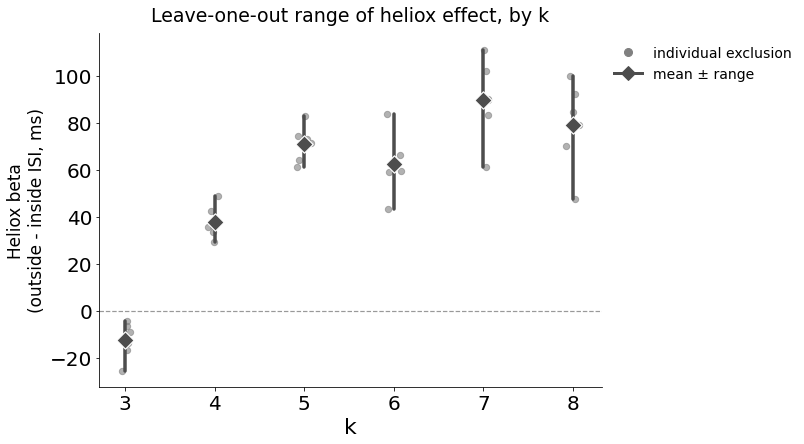

In [5]:
# Cell 5: Supp. Fig. S5A, leave-one-out range of the heliox effect
fig, ax = plt.subplots(figsize=(9, 6.5))
jitter = np.random.default_rng(0)                    # same jitter as the original figure
for r in loo.itertuples():
    ax.scatter(r.k + jitter.uniform(-0.08, 0.08), r.beta_ms, color='0.5', s=40, alpha=0.6, zorder=2)
for k, r in loo_summary.iterrows():
    ax.plot([k, k], [r['min'], r['max']], color='0.3', lw=3.5, zorder=3, solid_capstyle='round')
    ax.scatter(k, r['mean'], color='0.3', s=150, marker='D', zorder=4, edgecolor='white', linewidth=1.2)
ax.axhline(0, color='0.6', ls='--', lw=1.2, zorder=1)
ax.set_xticks(KS)
ax.tick_params(labelsize=20)
ax.set_xlabel('k', fontsize=22)
ax.set_ylabel('Heliox beta\n(outside - inside ISI, ms)')
ax.set_title('Leave-one-out range of heliox effect, by k', pad=12)
ax.legend(handles=[Line2D([0], [0], color='0.5', marker='o', lw=0, markersize=8, label='individual exclusion'),
                   Line2D([0], [0], color='0.3', marker='D', lw=3, markersize=10, label='mean ± range')],
          frameon=False, loc='upper left', bbox_to_anchor=(1.0, 1.0))
fig.savefig(os.path.join(FIG_DIR, 'figS5A_leave_one_out.png'))
fig.savefig(os.path.join(FIG_DIR, 'figS5A_leave_one_out.pdf'))
plt.show()

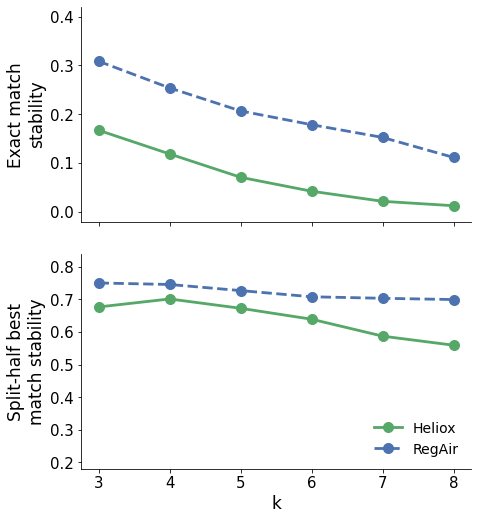

          exact_match        best_match       
condition      heliox regair     heliox regair
k                                             
3               0.167  0.308      0.677  0.751
4               0.119  0.254      0.702  0.746
5               0.071  0.207      0.673  0.727
6               0.042  0.178      0.639  0.708
7               0.022  0.152      0.587  0.704
8               0.013  0.111      0.559  0.700


In [6]:
# Cell 6: Supp. Fig. S5B, split-half stability of the selected k-grams
# exact: Jaccard similarity of the sets selected in two random halves of the bouts.
# best match: each k-gram of one half scored by its closest k-gram in the other (share of positions alike).
stab = stability.groupby(['condition', 'k'])[['exact_match', 'best_match']].mean()
fig, axes = plt.subplots(2, 1, figsize=(7, 8.5), sharex=True, gridspec_kw=dict(hspace=0.15))
for ax, col, ylabel, ylim in [(axes[0], 'exact_match', 'Exact match\nstability', (-0.02, 0.42)),
                              (axes[1], 'best_match', 'Split-half best\nmatch stability', (0.18, 0.84))]:
    for cond, color in [('heliox', '#55A868'), ('regair', '#4C72B0')]:
        s = stab.loc[cond]
        ax.plot(s.index, s[col], marker='o', markersize=10, lw=2.8, ls=COND_STYLE[cond], color=color,
                label=COND_LABEL[cond])
    ax.set_ylabel(ylabel)
    ax.set_ylim(*ylim)
axes[1].set_xticks(KS)
axes[1].set_xlabel('k')
axes[1].legend(frameon=False, loc='lower right')
fig.savefig(os.path.join(FIG_DIR, 'figS5B_split_half.png'))
fig.savefig(os.path.join(FIG_DIR, 'figS5B_split_half.pdf'))
plt.show()
print(stab.unstack(0).round(3).to_string())

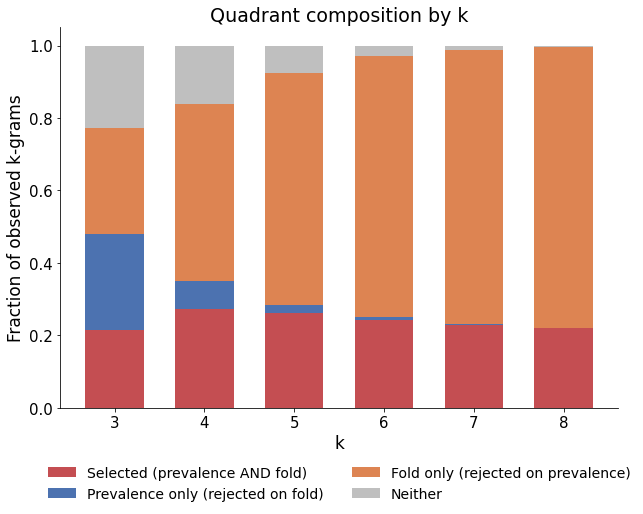

share of observed k-grams, pooled over birds and conditions:
outcome  selected  prev_only  fold_only  neither
k                                               
3           0.215      0.265      0.292    0.227
4           0.273      0.078      0.487    0.162
5           0.261      0.023      0.639    0.077
6           0.244      0.006      0.722    0.028
7           0.230      0.002      0.756    0.012
8           0.219      0.001      0.775    0.005

mean share per bird:
outcome  selected  prev_only  fold_only  neither
k                                               
3           0.284      0.305      0.224    0.188
4           0.400      0.096      0.378    0.127
5           0.422      0.029      0.495    0.054
6           0.422      0.007      0.552    0.019
7           0.417      0.002      0.574    0.008
8           0.411      0.001      0.585    0.003

change with k, fraction ~ k + (1 | bird):
  outcome  beta_per_k        p
 selected      0.0196   0.0327
prev_only     -0.0521 8.56e-

In [7]:
# Cell 7: Supp. Fig. S5C, what the two criteria keep and reject, by k
# Every observed k-gram (all birds, both conditions) falls in one of four groups.
passes_prev = kgrams['pct_bouts'] >= SET['PREVALENCE']
passes_fold = kgrams['fold'] >= SET['FOLD_CUT']
kgrams['outcome'] = np.select([passes_prev & passes_fold, passes_prev, passes_fold],
                              ['selected', 'prev_only', 'fold_only'], default='neither')
OUTCOMES = [('selected', 'Selected (prevalence AND fold)', '#C44E52'),
            ('prev_only', 'Prevalence only (rejected on fold)', '#4C72B0'),
            ('fold_only', 'Fold only (rejected on prevalence)', '#DD8452'),
            ('neither', 'Neither', '0.75')]
names = [o[0] for o in OUTCOMES]
pooled = pd.crosstab(kgrams['k'], kgrams['outcome'], normalize='index').reindex(columns=names, fill_value=0)

fig, ax = plt.subplots(figsize=(10, 7))
bottom = np.zeros(len(pooled))
for name, label, color in OUTCOMES:
    ax.bar(pooled.index.astype(str), pooled[name], bottom=bottom, color=color, label=label, width=0.65)
    bottom += pooled[name].to_numpy()
ax.set_xlabel('k')
ax.set_ylabel('Fraction of observed k-grams')
ax.set_title('Quadrant composition by k')
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=14)
fig.savefig(os.path.join(FIG_DIR, 'figS5C_selection_outcomes.png'))
fig.savefig(os.path.join(FIG_DIR, 'figS5C_selection_outcomes.pdf'))
plt.show()

# Does each group's share change with k? Shares per bird (both conditions together), then
# fraction ~ k + (1 | bird), as in the S5C legend.
per_bird = pd.crosstab([kgrams['bird'], kgrams['k']], kgrams['outcome'], normalize='index').reindex(columns=names, fill_value=0)
per_bird = per_bird.reset_index()
trend = []
for name in names:
    res = fit_ml('frac ~ k', per_bird[['bird', 'k', name]].rename(columns={name: 'frac'}))
    trend.append(dict(outcome=name, beta_per_k=res.params['k'], p=res.pvalues['k']))
trend = pd.DataFrame(trend)
print('share of observed k-grams, pooled over birds and conditions:')
print(pooled.round(3).to_string())
print('\nmean share per bird:')
print(per_bird.groupby('k')[names].mean().round(3).to_string())
print('\nchange with k, fraction ~ k + (1 | bird):')
print(trend.to_string(index=False, float_format=lambda v: f'{v:.3g}'))

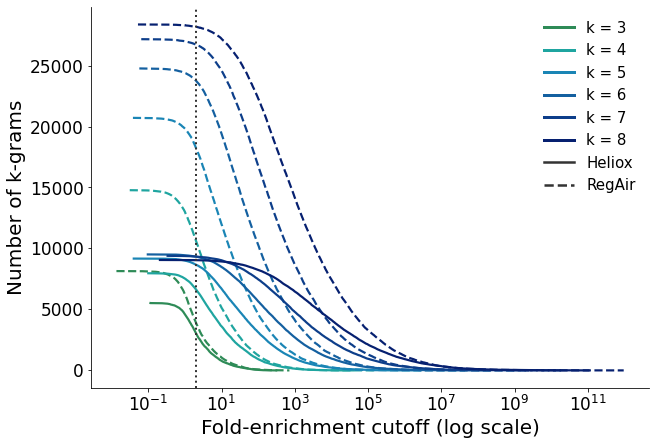

In [8]:
# Cell 8: Supp. Fig. S5D, how many k-grams pass each possible fold-enrichment cutoff
# k-grams whose expected count is 0 (infinite fold) pass every cutoff and are not drawn.
fig, ax = plt.subplots(figsize=(10, 7))
for k in KS:
    for cond in ['heliox', 'regair']:
        f = kgrams.loc[(kgrams['k'] == k) & (kgrams['condition'] == cond), 'fold'].to_numpy()
        f = np.sort(f[np.isfinite(f) & (f > 0)])
        ax.plot(f, np.arange(len(f), 0, -1), color=K_COLORS[k], ls=COND_STYLE[cond], lw=2.2)
ax.set_xscale('log')
ax.axvline(SET['FOLD_CUT'], color='0.2', ls=':', lw=2)
ax.set_xlabel('Fold-enrichment cutoff (log scale)', fontsize=20)
ax.set_ylabel('Number of k-grams', fontsize=20)
ax.tick_params(labelsize=17)
k_legend(ax, loc='upper right', fontsize=15)
fig.savefig(os.path.join(FIG_DIR, 'figS5D_fold_cutoff.png'))
fig.savefig(os.path.join(FIG_DIR, 'figS5D_fold_cutoff.pdf'))
plt.show()

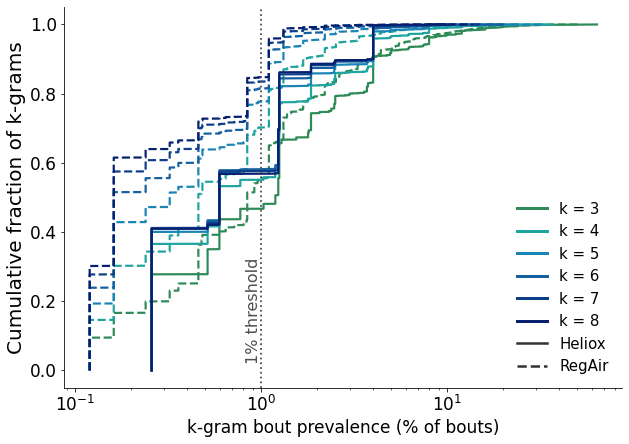

In [9]:
# Cell 9: Supp. Fig. S5E, distribution of k-gram bout prevalence
fig, ax = plt.subplots(figsize=(10, 7))
for k in KS:
    for cond in ['heliox', 'regair']:
        x = np.sort(kgrams.loc[(kgrams['k'] == k) & (kgrams['condition'] == cond), 'pct_bouts'].to_numpy() * 100)
        x = x[x > 0]
        ax.plot(x, np.arange(1, len(x) + 1) / len(x), color=K_COLORS[k], ls=COND_STYLE[cond], lw=2.2)
ax.set_xscale('log')
thr = SET['PREVALENCE'] * 100
ax.axvline(thr, color='0.3', ls=':', lw=1.8)
ax.text(thr, 0.02, f'{thr:g}% threshold', rotation=90, va='bottom', ha='right', fontsize=16, color='0.3')
ax.set_xlabel('k-gram bout prevalence (% of bouts)')
ax.set_ylabel('Cumulative fraction of k-grams', fontsize=20)
ax.tick_params(labelsize=17)
k_legend(ax, loc='lower right', fontsize=15)
fig.savefig(os.path.join(FIG_DIR, 'figS5E_prevalence.png'))
fig.savefig(os.path.join(FIG_DIR, 'figS5E_prevalence.pdf'))
plt.show()

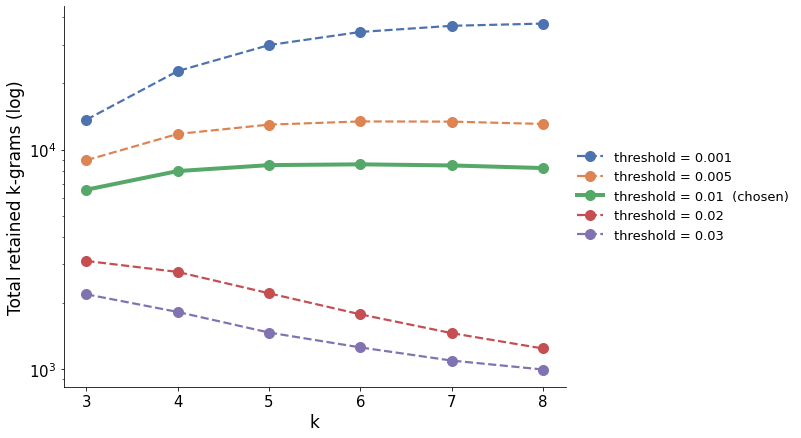

k          3      4      5      6      7      8
0.001  13667  22745  29878  34272  36556  37422
0.005   8942  11775  12983  13422  13397  13074
0.010   6564   7980   8493   8565   8465   8237
0.020   3112   2774   2218   1779   1461   1244
0.030   2195   1824   1470   1258   1096    998


In [10]:
# Cell 10: Supp. Fig. S5F, k-grams kept at each candidate prevalence threshold (prevalence alone),
# summed over birds and conditions
THR_COLORS = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B2']
kept = pd.DataFrame({thr: kgrams[kgrams['pct_bouts'] >= thr].groupby('k').size().reindex(KS, fill_value=0)
                     for thr in SET['THRESHOLD_SWEEP']})
fig, ax = plt.subplots(figsize=(9, 7))
for thr, color in zip(SET['THRESHOLD_SWEEP'], THR_COLORS):
    chosen = np.isclose(thr, SET['PREVALENCE'])
    ax.plot(KS, kept[thr], marker='o', markersize=10, lw=4 if chosen else 2.2, ls='-' if chosen else '--',
            color=color, label=f'threshold = {thr:g}' + ('  (chosen)' if chosen else ''))
ax.set_yscale('log')
ax.set_xticks(KS)
ax.set_xlabel('k')
ax.set_ylabel('Total retained k-grams (log)')
ax.legend(frameon=False, loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize=13)
fig.savefig(os.path.join(FIG_DIR, 'figS5F_prevalence_threshold.png'))
fig.savefig(os.path.join(FIG_DIR, 'figS5F_prevalence_threshold.pdf'))
plt.show()
print(kept.T.to_string())